# Functions and Differentiation
In the first part of the course we covered linear algebra. To deepen our understanding of the underlying mathematics, we now spend some time on the core ideas of **calculus**, or infinitesimal calculus, the umbrella term for differential and integral calculus.

Like linear algebra before it, most of this is a refresher of mathematics you should have seen at B-level (Danish high school).

Calculus gives us a framework for understanding the mechanics of mathematical functions. Calculus helps us:
* Understand the slope at different points
* Find the extreme points of a function

> **Note:** This notebook contains cells that fail *on purpose*. Cells marked **⚠️ Expected error** are meant to fail so we can practise reading error messages. All other cells should run from top to bottom without errors.


> ### Today's lesson
> * **Topic**: Functions and differentiation - slope, secants, limits, and tangents.
> * **Mathematics (refresher from B-level)**: linear functions, quadratic functions, the difference quotient.
> * **Python today**: `np.linspace`, `plt.plot`, `sympy.symbols`, `sympy.limit`, `sympy.diff`, `.subs()`.
> * **Remember**: Run the cells from top to bottom. If something behaves strangely: *Runtime → Restart session and run all*.


A linear function can be written as
$f(x) = ax + b$.

A quadratic equation can be written as $f (x) = ax^2 + bx + c$


We start by creating a running example that we'll refer back to throughout this section. The problem isn't a financial one, so we can focus on the mathematics for now. Let's assume we have the following equation, which describes the ball's trajectory after it is kicked by a football player:

$y = (-x^2) + 3x -1$

$x$ is time in seconds, while $y$ is the ball's vertical position. Naturally, we want to know the highest position the ball reached, and when that happened. We can plot the equation and estimate the result visually, but if we want the precise time and vertical position we need calculus. In this course we explore the various calculus concepts needed to build up to being able to find this point.

Let's start by visualizing this function.




**Exercise**

* Use numpy.linspace() to generate a NumPy array containing **100** values from **0** to **3** and assign it to $x$.
* Transform $x$ by applying the function: $y = (-x^2) + 3x -1$. Assign the result to $y$.
* Use pyplot.plot() to generate a line chart with $x$ on the x-axis and $y$ on the y-axis.
* Consider how you might calculate the max height, and the precise time it occurred.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

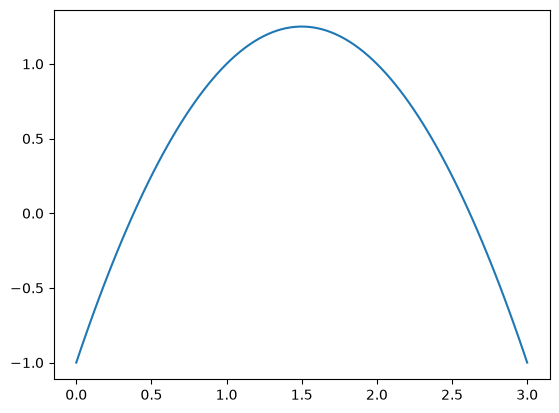

In [2]:
x = np.linspace(0, 3, num=100)
y = (-x**2)+3*x-1

plt.plot(x,y)

#### Calculus and linear algebra
Before we dive into analyzing the curve of a ball's height, we first need to understand a few central concepts. We'll explore these concepts using simple, straight lines first and then build up to applying them to curves. A simple, straight line is more precisely defined as a linear function. All linear functions can be written in the following form:

$y = ax + b$

For a given linear function, $a$ and $b$ are constant values, while $x$ and $y$ are variables. $y = 3x + 1$ and $y = 5$ are both examples of linear functions.

Let's focus on the function $y = 3x + 1$ for now. This function multiplies any $x$ value we add by 3 and then increases the value by 1.


Let's start by developing a geometric understanding of linear functions. Below you'll find a figure that can help you understand how the line shifts or changes when you change the values of $a$ and/or $b$.
* How does the line change when you keep $a$ fixed but vary $b$?
* How does the line change when you keep $b$ fixed but vary $a$?
*	Which value controls the steepness of the line?
*	What happens to the line when $a$ is set to 0?


In [3]:
# np.arange(start, stop) creates a sequence of integers - stop is NOT included, so we use 7 to reach up to 6
x = np.arange(-5, 7)
print(x)


[-5 -4 -3 -2 -1  0  1  2  3  4  5  6]


In [4]:
y = 3*x + 1
print(y)

[-14 -11  -8  -5  -2   1   4   7  10  13  16  19]


In [5]:
import IPython

In [6]:
iframe = '<iframe src="https://www.desmos.com/calculator/efglhmyz8f" width="1000px" height="500px" style="border: 1px solid #ccc" frameborder=0></iframe>'
IPython.display.HTML(iframe)

/content


#### The line's rate of change
From the previous step we can tell that the constant $a$ determines how *steep* the line is.
When $a$ equals 0, the line is completely flat and parallel to the x-axis. When $a$ and $b$ are both set to 0, the line coincides with the x-axis.

The $a$-value controls a line's slope, while the $b$-value controls the line's y-intercept. These terms will be elaborated on further. The y-intercept is the value where the line crosses the y-axis. When you held $a$ fixed but varied $b$, you may have noticed that the point where the line crossed the y-axis varied. The line crosses the y-axis when $x$ is 0. For $y = 3x + 1$, the y-intercept is:

$f(0) = 3(0) + 1 = 1$

While the y-intercept describes where a line crosses the y-axis, the slope describes the line's steepness. In the last step, when we set $a$ to a positive value, the y-values increased as the x-values increased. When we set $a$ to a negative value, the y-values decreased as the x-values increased. When $a$ was 0, the y-value was constant (and so was the y-intercept).


* Positive slope: The line rises as you move from left to right.
* Negative slope: The line falls as you move from left to right.
* Zero slope: The line is horizontal.
* Undefined slope: The line is vertical.


Another way to think about slope is **rate of change**. The rate of change is how much the y-axis changes for a given change in the x-axis.

$a = \frac{\text{change in y}}{\text{change in x}} = \frac{\Delta y}{\Delta x}$

Here is the slope calculation between the points (1,4) and (4,13), both of which are points on the line $y = 3x + 1$:

$a = \frac{\text{change in y}}{\text{change in x}} = \frac{13-4}{4-1} = 3$

When we need to write unique $x$ and $y$ coordinates, we usually add an index number (subscript). For example, the points (1,4) and (4,13) from the last calculation can be called ($x_1, y_1$) and ($x_2, y_2$). If we don't specify what ($x_1, y_1$) and ($x_2, y_2$) are, they act as variables. We emphasize this further in the figure for this step, and again when we examine the calculations in the next step.

The following figure contains a visualization of $y = 3x + 1$ with 2 coordinates highlighted. Try varying the $x_1$ and $x_2$ values and observe the visualization of the rate of change. Both the coordinates ($x_1, y_1$) and ($x_2, y_2$) are highlighted on the line. The calculation of the rate of change is also shown in the plot's title. You'll notice that
no matter what the coordinates are, the rate of change between them is always 3.



In [7]:
iframe = '<iframe src="https://www.desmos.com/calculator/jh1zb3n9al" width="1000px" height="500px" style="border: 1px solid #ccc" frameborder=0></iframe>'
IPython.display.HTML(iframe)

#### Rate of change and the function's slope
If we calculate the rate of change between points on a line, it will always equal the function's slope. Let's show this for the more general case. In what follows, ($x_1, y_1$) and ($x_2, y_2$) represent 2 arbitrary coordinates on a line:

$y_1 = ax_1 + b$

$y_2 = ax_2 + b$

We can subtract these two equations to get:

$y_1 - y_2 = ax_1 - ax_2 + b - b$

$y_1 - y_2 = a(x_1 - x_2)$

$a = (y_1 - y_2)/(x_1 - x_2)$

Here, $y_1 - y_2$ represents $\Delta y$, and $x_1 - x_2$ represents $\Delta x$. Let's calculate the slope for a few more points lying on $y = 3x + 1$.


**Exercise**
* Write a function called slope() that calculates the rate of change between two coordinates.
* This function should accept 4 parameters representing 2 x-values and 2 y-values for 2 different points: $x1$, $x2$, $y1$, $y2$
* Calculate the rate of change between (0,1) and (4,13) and assign
it to slope_1.
* Calculate the rate of change between (5,16) and (-1, -2) and assign it to slope_2.
* Calculate the rate of change between 2 points from the visualization




In [8]:
def slope(x1, x2, y1, y2):
  a = (y2-y1)/(x2-x1)
  return a

In [9]:
slope_1 = slope(0,4,1,13)

In [10]:
slope_2 = slope(5,-1,16,-2)

In [11]:
print(slope_1)
print(slope_2)

3.0
3.0


## Non-linear functions
So far we've worked with linear functions, where we can determine the function's slope directly from the equation itself. But if we return to our equation for the ball's trajectory, you'll notice that it doesn't match the form $y = ax + b$:

$y = -(x^2) + 3x - 1$

This is because this function is a **non-linear function**. Non-linear functions don't represent straight lines - they represent curves like the one we introduced in the first part of this session. The outputs of a non-linear function are not proportional to the input values $x$. An increment in $x$ does not result in a constant increment in $y$.

When $x$ is raised to a power that is not equal to $1$, we have a non-linear function. Here are a few more examples of non-linear functions:

$y = x^3$

$y = x^3 + 3x^2 + 2x -1$

$y = \frac{1}{-x^2}$

$y = \sqrt{x}$

In the following figure you can observe how the slope changes for different values of $x_1$ and $x_2$ - here I've just used $a$ and $b$ because of the interface.


In [12]:
iframe = '<iframe src="https://www.desmos.com/calculator/wiirw9ca6h" width="1000" height="500px" style="border: 1px solid #ccc" frameborder=0></iframe>'
IPython.display.HTML(iframe)


#### The secant
As you changed $x_1$ and $x_2$, the slope between the 2 points varied drastically. This is because linear functions have a constant slope throughout, so we know the slope at every point on the line. If we knew that the relationship between temperature and wind speed was linear, we could predict what the wind speed would be at any temperature by trying two points and calculating the slope.

If the relationship were instead non-linear, we could not predict what the wind speed would be at any particular temperature just by measuring 2 points and computing the slope between them (because the slope changes drastically depending on which 2 points you choose). When we calculate the slope between 2 points on a curve, we're actually calculating the slope of the line that intersects both of these points.

As you know, the equation for a linear function is $y = ax + b$ - for secants and tangents we call the slope $m$. If we know the values of $m$, $x$, and $y$, we can calculate $b$, or the y-intercept, using some arithmetic. Let's go through the calculation for the line connecting the points at x-values $0$ and $1$.

First, we state what we know.

$y = -(x^2) + 3x -1$

$x_1 = 0$

$x_2 = 1$

We use $y = -(x^2) + 3x -1$ to calculate $y_1$ and $y_2$.

$y_1 = 0 + 0 - 1 = -1$

$y_2 = -1 +3 -1 = 1$

We use the coordinates (x,y) to solve for the slope.

$m = \frac{y_2 - y_1}{x_2 - x_1} = \frac{2}{1} = 2$

Because both ($x_1, y_1$) and ($x_2, y_2$) are points on the line, we can use either one to calculate the y-intercept value ($b$).

$y_1 = mx_1 + b$

$-1 = 2(0) + b$

$b = -1$

Finally, we can use the slope and the y-intercept to form the equation for
the line connecting both points:

$y = 2x -1$

A line that intersects 2 points on a curve is known as a **secant line**. Let's practice creating some secant lines for our curve. We've done some of the groundwork to build the function **draw_secant()**, which right now just plots our non-linear function between the x-values -20 and 30.


**Exercise**

Let's try defining the function **draw_secant()**, which accepts 2 x-values as a list
and draws the secant line connecting these 2 points. This function should:

* Determine the y-values for these 2 x-values using our non-linear function.
* Calculate the slope between these 2 points.
* Calculate the y-intercept using arithmetic.
* Plot the secant line using the color "green".
* Show all the plots within the function.

Use the draw_secant() function to generate 3 plots:
* A visualization of the secant line between x-values 3 and 5.
* A visualization of the secant line between x-values 3 and 10.
* A visualization of the secant line between x-values 3 and 15


In [13]:
def draw_secant(x_values):
    # draw function
    x = np.linspace(-20,30,100)
    y = -1*(x**2) + x*3 - 1
    plt.plot(x,y)

    # get x1 and x2
    x1 = x_values[0]
    x2 = x_values[1]

    # calculate y-values from x1 and x2
    y1 = -1*(x1**2) + x1*3 - 1
    y2 = -1*(x2**2) + x2*3 - 1

    # slope m and intercept calculated here
    m = (y2-y1)/(x2-x1)
    b = y1-m*x1

    # formula for the secant
    s = m*x+b

    plt.plot(x,s, c='green')


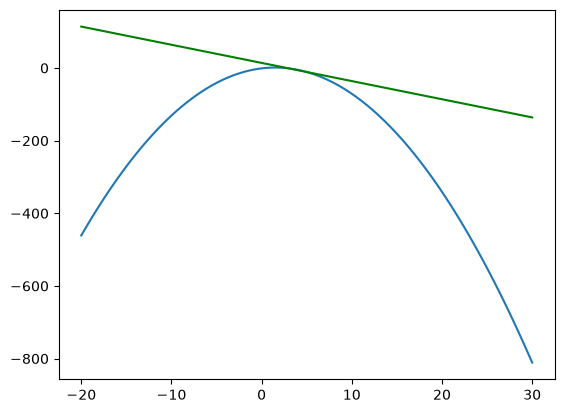

In [14]:
draw_secant([3,5])

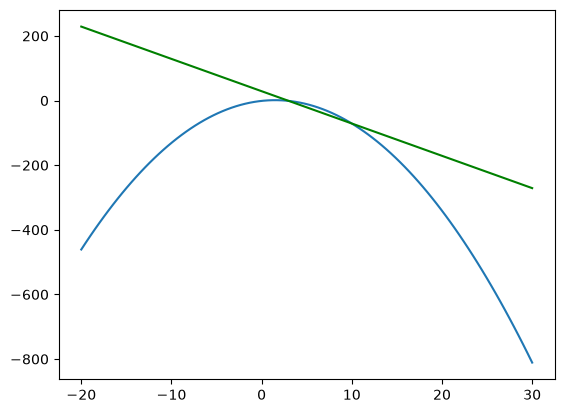

In [15]:
draw_secant([3,10])

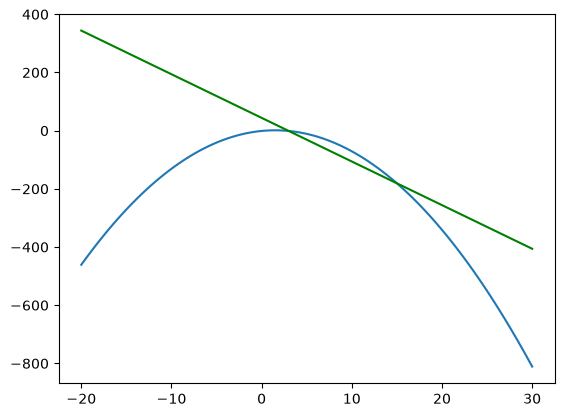

In [16]:
draw_secant([3,15])

### The slope of the curve
In the above, we plotted secant lines between the fixed $x_1$ value and increasingly larger $x_2$ values. When the distance between $x_1$ and $x_2$ was small, the secant line lined up closely with our curve. As we increased the distance between the 2 x-values, the secant line began to diverge from our curve. This observation is critical to understanding how slope works for curves.

The slope of a curve at a particular point is best understood as the slope of the secant line with increasingly smaller intervals of $[x_1, x_2]$. The smaller the difference between $x_1$ and $x_2$, the more precisely the secant line approximates the slope at that point on our curve.


#### The curve's slope value
When $x_1$ and $x_2$ have the same value, the slope value is **undefined**. This is because **division by 0** has no meaning in mathematical calculations.

$m = \frac{-1--1}{3-3} = \frac{0}{0} = \text{undefined}$

However, as $x_2$ approaches $x_1$ from either side of the curve, the slope of the secant line gets close to -3. Here is a table showing the slope values for increasingly narrower gaps between $x_2$ and $x_1$:


$$
\begin{matrix}
\hline
\textbf{x2} & \textbf{x1} & \textbf{m} \\ \hline
2.9         & 3           & -2.9       \\
2.99        & 3           & -2.99      \\
2.999       & 3           & -2.999     \\
3.01        & 3           & -3.01      \\
3.001       & 3           & -3.001     \\
3.0001      & 3           & -3.0001    \\ \hline
\end{matrix}
$$



Although we can't calculate the slope at the point where $x_0 = x_1 = 3$, we can infer from the table and graph in the last step that it approaches -3. This value is known as **the instantaneous rate of change**, because it describes the slope at a specific point. In linear functions, the instantaneous rate of change at any point on the line is the same. In
non-linear functions, the instantaneous rate of change describes the steepness of the function's graph at a particular point.

This line is known as **the tangent**, and unlike the secant line, it intersects our function at only one point. So far we've worked with secant lines connecting 2 points that are closer together. You can think of the tangent line as the secant line when both points are the same. For now, we'll need to learn to work with the undefined value we get when we try to calculate the tangent line directly.



## The tangent and the curve's slope
We've now tried fixing a first point on our curve, drawn a secant line between the first point and a second point, and observed what happened as we moved the second point closer to the first point along the curve. The larger the interval between the 2 points on the x-axis, the more the secant line's slope deviates from the curve's slope. The closer the interval, the more the secant line began to match the steepness at the first point on the curve.

In this part we formalize the idea of slope further and see how to **calculate the slope for non-linear equations at a given point**. As you work through the rest of this course, we recommend following the math presented using pencil and paper. We start by introducing a mathematical notation that formalizes the observation we just made.

You may have heard of this before, in gymnasium (Danish high school), under the term **difference quotient**. The difference quotient is the change in the function ($y_2-y_1$) divided by $(x_2-x_1)$, which is also often written as $h$. So:

 $$a_s=\frac{y_2-y_1}{x_2-x_1}=\frac{f(x_0+h)-f(x_0)}{(x_0+h)-x_0}=\frac{f(x_0+h)-f(x_0)}{h}$$

 or

 $$a_s=\frac{\Delta y}{h}=\frac{f(x_0+h)-f(x_0)}{h}$$

 If we try to "bring together" our $x_1$ and $x_2$ values – i.e. $x_1 = x_2$ – we run into the division-by-zero problem:

$$m = \frac{f(x_2)-f(x_1)}{x_2 - x_1} = \frac{0}{0}$$

Although the slope is undefined when $x_1$ and $x_2$ are equivalent, we'll still be able to work out and justify which value the slope approaches as $x_1$ approaches $x_2$. To do this, we need to reformulate the problem as a **limit**. The limit describes the value a function approaches as the function's input variable approaches a particular value. In our case the input variable is $x_2$ and our function is $m = \frac{f(x_2)-f(x_1)}{x_2 - x_1}$. The following mathematical notation formalizes the statement "as $x_2$ approaches $3$, the slope between $x_1$ and $x_2$ approaches $-3$", using the limit:

$$\lim_{x2\to3}\frac{f(x_2)-f(x_1)}{x_2 - x_1} = -3$$


$\lim_{x_2\to3}$ is another way of saying "as $x_2$ approaches $3$". Because we fixed $x_1$ to $3$, we can replace $x_1$ with $3$ in the function:

$$\lim_{x_2\to3}(\frac{f(x_2)-f(3)}{x_2 - 3}) = \lim_{x2\to3}\frac{f(x_2)+1}{x_2 - 3} = -3$$

Formally, we can also say that the **derivative** is the limit of the **difference quotient** as h approaches 0.

$$a_t=\lim_{h\to0}(a_s)=\lim_{h\to0}(\frac{\Delta y}{h})$$

We still need to prove that this limit actually equals $-3$, which we'll spend the rest of today's session looking at.




#### Limits
There are two kinds of limits - **defined limits** and **undefined limits**. As you might guess, the limit we looked at in the last section was an undefined limit, because substituting $3$ for $x_2$ results in an undefined value. A defined limit can be evaluated simply by substituting the value into the limit.

$$
\begin{matrix}
\hline
\textbf{x2} & \textbf{x1} & \textbf{m} \\ \hline
2.9         & 3           & -2.9       \\
2.99        & 3           & -2.99      \\
2.999       & 3           & -2.999     \\
3.01        & 3           & -3.01      \\
3.001       & 3           & -3.001     \\
3.0001      & 3           & -3.0001    \\ \hline
\end{matrix}
$$

Let's start by understanding how defined limits work. When the resulting value of a limit is defined at the value the input variable is approaching, we say the limit is defined. Above is a table of values showing the slopes of the secant lines between points that get closer and closer to $x_1 = 3$:


To calculate each of these slopes we used both values in the slope equation. Here is the calculation for the slope of the secant line between the points at $x_1 = 3$ and $x_2 = 2.9$ where $f(x) = -(x^2) + 3x -1$:

$$m = \frac{f(2.9) - f(3)}{2.9-3} = -2.9$$

We can actually rewrite each of these as defined limits. For example, the following defined limit describes the slope of the secant line between the same 2 points:

$$\lim_{x2\to2.9}\frac{f(x_2) - f(x_1)}{x_2-x_1}$$

Since we fixed $x_1$ to the value $3$, we can replace $x_1$ with $3$ and $f(x_1)$ with $-1$:

$$\lim_{x2\to2.9}\frac{f(x_2) - (-1)}{x_2-3}$$

To solve for the limit we can substitute $2.9$ directly for $x_2$. This is because the limit is defined at the specific value ($2.9$) that the input variable ($x_2$) is approaching. More precisely: because the function is a polynomial and therefore continuous at that point, the limit equals the function value — so direct substitution is allowed here. When we can replace the input variable with the value it's approaching in the limit, the problem converts to an ordinary arithmetic problem:

$$\frac{f(2.9) - (-1)}{2.9-3} = -2.9$$

Hopefully this process has shown how we can solve undefined limits like the one we presented in the first section. **By rewriting and converting an undefined limit into a defined limit, we can solve the limit using direct substitution and standard arithmetic**.

Before we dive into how to convert an undefined limit into a defined limit, let's first examine how to calculate limits using Python, to verify our approach.


#### SymPy and calculus
The SymPy package has a number of functions that let us calculate limits. SymPy's syntax follows mathematical notation quite closely. To start, we need to import the package and use sympy.symbols() to define the variables we want to work with as symbols, so that SymPy can operate on them:


In [17]:
# Importing sympy
import sympy


So far we've primarily visualized a function by generating many $x$ values (and defining them as the object x), transforming these $x$ values into $y$ values (and defining them as the object y) using basic Python arithmetic operators, and using matplotlib to plot both lists of numbers:


In [18]:
# With numpy, x is a collection of concrete numbers
x = np.linspace(0, 3, 100)
print(type(x))


<class 'numpy.ndarray'>


In SymPy the workflow is different, and the Python variables we use don't directly hold specific values. In SymPy, Python variables are linked directly to variables in mathematics. We express a mathematical function as a transformation of the Python variable. When you use sympy.symbols() and assign it to x, x points to a special SymPy object (not a list):


In [19]:
# Define symbols using SymPy
x,y = sympy.symbols('x y')


In [20]:
# Check what kind of Python object x is now
print(type(x))


<class 'sympy.core.symbol.Symbol'>


What we need to do now is write the mathematical function in SymPy. We use standard Python arithmetic operators for this:


In [21]:
# Define the function x^2 + 3x
y = (-x**2)+3*x-1


In [22]:
y

-x**2 + 3*x - 1

**Exercise:**

* Try expressing $y = x^2 + 1$ using '**' to write $x^2$.
* Visualize y using the print() function. What is the result?
* What happens when you run $y = 3(x)$ in Python?


In [23]:
#Define symbols in SymPy
x,y = sympy.symbols('x y')


A note on SymPy's functionality. Unlike numpy, SymPy is built to visualize mathematical solutions graphically, and will therefore behave differently with the print function. The difference can be seen below:


In [24]:
# Using SymPy's functionality
y = x**2 + 1


In [25]:
# The correct way to display with sympy
y


x**2 + 1

In [26]:
# Sympy and print
print(y)


x**2 + 1


And the exercise's last question - what happens when you run $y = 3(x)$?


In [27]:
# ⚠️ Expected error — this cell is supposed to fail
# What happens here? Run the cell and read the error message from the bottom up
y = 3(x)


<>:3: SyntaxWarning: 'int' object is not callable; perhaps you missed a comma?
<>:3: SyntaxWarning: 'int' object is not callable; perhaps you missed a comma?
/var/folders/7v/frqfmbs922n1szkk4rqhmnz00000gp/T/ipykernel_16514/3362267017.py:3: SyntaxWarning: 'int' object is not callable; perhaps you missed a comma?
  y = 3(x)


TypeError: 'int' object is not callable

Python reads `3(x)` as *"call the number 3 as a function with the argument x"* - and numbers can't be called, so we get a `TypeError: 'int' object is not callable`. In mathematics, $3(x)$ implies multiplication, but in Python, multiplication must always be written explicitly: `3*x`. This is one of the most common mistakes when translating mathematics into code.


In [28]:
# Print formulas in LaTeX (markdown) format
sympy.latex(y)


'x^{2} + 1'

Inserted into markdown LaTeX: $x^{2} + 1$


#### More useful SymPy functions
Besides defining and rewriting expressions, SymPy has a number of functions we'll need in the exercises and the rest of the course:

* `sympy.expand()` expands an expression - e.g. $(x+2)^2$ to $x^2 + 4x + 4$.
* `sympy.simplify()` shortens and reduces an expression as much as possible.
* `sympy.solve()` solves an equation - it expects the form $expression = 0$, so e.g. $x^2 = 25$ is first rewritten as $x^2 - 25 = 0$.


In [29]:
# expand: expand an expression
print(sympy.expand((x + 2)**2))

# simplify: reduce an expression as much as possible
print(sympy.simplify((x**2 - 25) / (x - 5)))

# solve: solve the equation x**2 = 25 (rewritten to the form x**2 - 25 = 0)
print(sympy.solve(x**2 - 25, x))


x**2 + 4*x + 4
x + 5
[-5, 5]


#### Limits in SymPy
Once we've defined the variables and the mathematical function in SymPy, we use the sympy.limit() function to calculate the limit. This function takes 3 parameters:
* The function we want the limit of
* The input variable
* The value the input variable is approaching

From here we work through a few new limit problems to understand the basic ideas. Let's say we wanted to solve the following defined limit:

$$\lim_{x\to1}x^2 + 1$$

For this problem, the input variable is $x$ and the limit criterion is $\lim{x\to1}$. Here's how this can be expressed in SymPy:


In [30]:
# With the formula directly in the SymPy function
# the first parameter is your function, the second is the input variable (x), and the third parameter is the value the input variable approaches for the limit being calculated.
limit_one = sympy.limit(x**2 + 1, x, 1)


In [31]:
limit_one

2

In [32]:
# With a predefined formula
# Define function
y = x**2 + 1
#calculate limit
limit_two = sympy.limit(y, x, 1)


In [33]:
limit_two

2

Let's practice using SymPy.

**Exercise:**
* Use SymPy to confirm that $\lim_{x_2\to2.9}\frac{f(x_2) - (-1)}{x_2 -3} = -2.9$. You need to define $x_2 = 2.9$ as well as $f(x) = - (x^2) + 3x - 1$ before passing the limit function to sympy.limit().
* Define the result of the limit calculation as the object **limit_one**. Visualize it using the print() function.


In [34]:
# Define x2 as a symbol
x2 = sympy.symbols('x2')

# define our limit function
f_lim = (((-(x2**2)+3*x2-1))-(-1))/(x2-3)

# use the limit function to find the limit of our f_lim as x2 approaches 2.9
limit_one = sympy.limit(f_lim, x2, 2.9)

print(limit_one)


-2.89999999999999


In [35]:
# using SymPy's display style
limit_one


-2.89999999999999

SymPy also has a function for replacing symbols with a constant (a specific number)


In [36]:
# Define function
f_x = -(x**2)+3*x-1


In [37]:
# define symbols
x, x1, x2 = sympy.symbols('x, x1, x2')


In [38]:
# Substitute x with a constant
f_x1 = f_x.subs(x, 3)


In [39]:
# the value of y (f_x1) when x = 3
f_x1


-1

## Properties of limits
SymPy calculates $-2.9$ as the slope of the secant line, matching our calculation using the slope formula. Before we can convert undefined limits into defined limits, we first need to understand a few properties of limits. Using these properties, we can transform undefined limits into defined limits and solve them. Here's the first property:

#### Limits of a sum or difference

$$\lim_{x\to a}[f(x) + g(x)] = \lim_{x\to a}f(x) + \lim_{x\to a}g(x)$$

This property lets us split limits that are summed into their individual components. The same applies to subtraction:


$$\lim_{x\to a}[f(x) - g(x)] = \lim_{x\to a}f(x) - \lim_{x\to a}g(x)$$

We can apply these rules to split the following limit into smaller components:

$$\lim_{x\to 1}[3x^2 + 3x - 3]$$

Although this is a defined limit, and we can solve it using direct substitution, it's a good example for understanding how to apply these properties. Applying the property we just learned, the equation splits into:

$$\lim_{x\to 1}[3x^2] + \lim_{x\to 1}[3x] - \lim_{x\to 1}[3]$$

Now let's substitute $x = 1$ into each of these limit terms.

$$3 + 3 - 3 = 3$$

Although we won't dive into the proofs of these limit properties in this session, you can read more about them [here](https://tutorial.math.lamar.edu/Classes/CalcI/LimitProofs.aspx#Extras_Limit_LimitProp). Let's use SymPy to confirm this result.

#### Splitting off a term multiplied by a constant

The second property lets us split off terms that are multiplied by a constant:

$$\lim_{x \to a} [cf(x)] = c \lim_{x \to a} f(x)$$

Applying it to the limit above, it becomes:

$$3 \lim_{x \to 1} [x^2] + 3 \lim_{x \to 1} [x] - 3 \lim_{x \to 1} [1]$$

and direct substitution gives the same answer: $3 + 3 - 3 = 3$.

Note: SymPy applies these rules internally itself when `limit()` calculates a limit - we split it apart once below to see what happens under the hood. You'll try out the constant rule yourselves in the exercises.


**Exercise**

* Use SymPy to calculate $lim_{x\rightarrow 1}[3x^2 + 3x -3]$.
* Assign the result to **limit_two**, and visualize it using the print() function.


In [40]:
# Define x as a symbol
x = sympy.symbols('x')


In [41]:
# Calculate the limit as x approaches 1
limit_two = sympy.limit(3*(x**2)+3*x-3, x, 1)


In [42]:
# Print
print(limit_two)

3


Split up $3x^2 +3x -3$


In [43]:
# The limits of the split-up function (with x=1)
#First part of the function
lim1 = sympy.limit(3*(x**2), x, 1)

# Second part of the function
lim2 = sympy.limit(3*x, x, 1)

# Third part of the function
lim3 = sympy.limit(-3, x, 1)

# Limit of the combined function
lim1 + lim2 + lim3


3

This operation therefore tells us that the closer x is to 1, the closer y will be to 3. This can also be written as $f(1) = 3$


#### From undefined to defined limit
To wrap up this session, we can convert the original undefined limit that calculated the slope at $x = 3$ into a defined limit:

$$\lim_{x_2 \to 3} \frac{f(x_2) + 1}{x_2 - 3} =$$

Because $f(x) = -(x^2) + 3x - 1$, we can expand $f(x_2)$.

$$\lim_{x_2 \to 3} \frac{-x_2^2+3x_2 -1 + 1}{x_2 - 3}$$

This can be reduced to:

$$\lim_{x_2 \to 3} \frac{-x_2^2+3x_2 }{x_2 - 3}$$

We still can't substitute directly to solve this limit because of the denominator. We need to find a way to cancel the denominator or convert it into a form that lets us substitute $3$ for $x_2$. If we factor $x_2$ out of the numerator, we can see something interesting:

$$\lim_{x_2 \to 3} \frac{x_2(-x_2 + 3) }{x_2 - 3}$$

If we also factor out $-1$, we can cancel $x_2 -3$ from the denominator with the same term in the numerator:

$$\lim_{x_2 \to 3} \frac{-x_2(x_2 - 3) }{x_2 - 3}$$

This can be rewritten as:

$$\lim_{x_2 \to 3} -x_2$$

Now we can substitute directly, which gives us $-3$. In this case we didn't need to use the properties of limits we looked at earlier. In the next part we'll see how to derive the general function that gives us the slope at any point on the curve, and there we will need to use these properties. For now, let's check what we just worked through "by hand" using SymPy.



**Exercise**

- Use SymPy to find $\lim_{x_2 \to 3} \frac{f(x_2) + 1}{x_2 - 3}$
- Save the solution as **limit_four**


In [44]:
# Define function
f_x2 = -(x2**2)+3*x2-1

# Use SymPy to find the limit when x2 = 3
limit_four = sympy.limit((f_x2+1)/(x2-3), x2, 3)


In [45]:
limit_four

-3

In [46]:
(f_x2+1)/(x2-3)

(-x2**2 + 3*x2)/(x2 - 3)

In [47]:
sympy.simplify((f_x2+1)/(x2-3))

-x2

## SymPy in practice - Calculating and plotting the tangent (with manual steps)

How do we calculate and plot (with the tools we have so far) the tangent at $x_0 = 0.5$ for a function called $f(x) = -x^2 + 3x - 1$?

$x_0$ refers to the starting value.


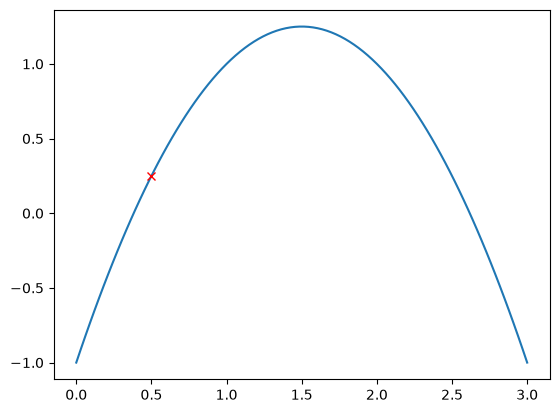

In [48]:
# Example with a tangent where x0 = 0.5
#Define x as a space
x = np.linspace(0, 3, num=100)
# Define y as a function
y = -(x**2)+3*x-1

# Plot the function
plt.plot(x,y)
# Mark a point on the x,y axes
plt.plot(0.5, 0.25, 'x', color='red')


First, $x_0$​ is defined as $0.5$, and $y0$​ is calculated using the function $f(x)=−x^2+3x−1$


In [49]:
# define x0 as 0.5
x0 = 0.5

# Define y0 as a function of x0
y0 = -(x0**2)+3*x0-1

# Show y0
print(y0)


0.25


 Recall that we can calculate the slope at $x_0$

 $$m=\frac{y_2-y_1}{x_2-x_1}=\frac{f(x_0+h)-f(x_0)}{(x_0+h)-x_0}=\frac{f(x_0+h)-f(x_0)}{h}$$

 or

 $$m=\frac{\Delta y}{h}=\frac{f(x_0+h)-f(x_0)}{h}$$


 Precisely, $h$ is the small change in the $x$-value, and $m$ is the slope of the tangent, which we find by calculating the limit of the difference quotient


SymPy is imported, and the symbols $x0$​ and $h$ are defined.


In [50]:
# setting up the difference quotient
#importing sympy
from sympy import symbols, diff, solve, limit, simplify, expand # import what we need from SymPy

#Define symbols
x0, h = symbols('x0, h')


The function $f(x0)$ is defined symbolically again


In [51]:
# Define function
f_x0 = -(x0**2)+3*x0-1


In [52]:
#Show the function of x0
f_x0


-x0**2 + 3*x0 - 1

The function $f(x0+h)$ is calculated by substituting $x0$​ with $x0+h$.


In [53]:
# Substitute x0 with x0+h
f_x0h = f_x0.subs(x0, x0+h)


In [54]:
# show the function with x0+h
f_x0h


3*h + 3*x0 - (h + x0)**2 - 1

The difference quotient $m=\frac{f(x_0+h)−f(x_0)}{h}$ is calculated


In [55]:
# the difference quotient - we call the slope m, as in the formula above
m = (f_x0h-f_x0)/h


In [56]:
m

(3*h + x0**2 - (h + x0)**2)/h

The limit of the difference quotient is calculated as $h$ approaches 0, to find the slope of the tangent.


In [57]:
# Calculating the limit
m_x0 = limit(m, h, 0)


In [58]:
m_x0

3 - 2*x0

The slope of the tangent is evaluated at $x0=0.5$.


In [59]:
# Substitute x0 with 0.5
m_x0.subs(x0, 0.5)


2.00000000000000

The y-intercept $b$ for the tangent is found.


In [60]:
# tangent - ordinary linear function (fx_t) = mx + b; We can substitute in x0 and y0

# 0.25 = 2*0.5 + b

b = 0.25 - 2*0.5
print(b)


-0.75


So our tangent at $x_0$ is: $t = 2x - 0.75$ and now we can also plot it


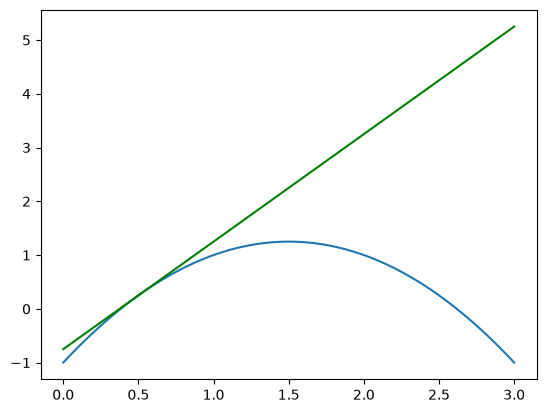

In [61]:
#Define x as a space
x = np.linspace(0, 3, num=100)
# define the function of y
y = -(x**2)+3*x-1

#Plot x and y
plt.plot(x,y)

# define the tangent function
t = 2*x - 0.75

# Plot the tangent
plt.plot(x,t, color='green')


# The simplest approach to visualizing a tangent using SymPy, NumPy, and Matplotlib


In [62]:
import numpy as np
import matplotlib.pyplot as plt

In [63]:
from sympy import symbols, diff, limit

# Define x as a symbol
x = symbols('x')

#Define the function f_x
f_x = (-x**2)+3*x-1


In [64]:
# Calculate the derivative of f(x)
f_prime = diff(f_x, x)


In [65]:
# Show f_prime
f_prime


3 - 2*x

In [66]:
# Evaluate the derivative at x = 2
tangent_slope = f_prime.subs(x, 2)


In [67]:
# Show the derivative
tangent_slope


-1

In [68]:
# Solve f(x) at x = 2
f_at_x = f_x.subs(x, 2)


In [69]:
# Show the position of y at x=2
f_at_x


1

In [70]:
# Generate x-values for the function
x_vals = np.linspace(-10, 10, 400)

# Generate y-values based on the function we've set up
# y_vals must match the equation being solved
y_vals = (-x_vals**2)+3*x_vals-1


In [71]:
# Calculate y-values for the tangent at x=2
y_tangent = tangent_slope * (x_vals - 2) + f_at_x


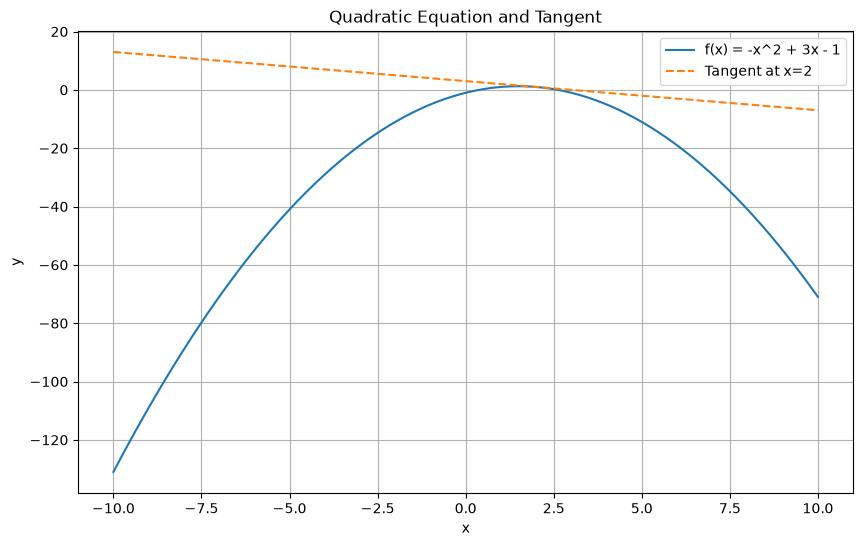

In [72]:
# Create a plot
plt.figure(figsize=(10, 6))

#plot the quadratic equation
plt.plot(x_vals, y_vals, label='f(x) = -x^2 + 3x - 1')

#plot the tangent
plt.plot(x_vals, y_tangent, label='Tangent at x=2', linestyle='--')

#plot xlabel
plt.xlabel('x')

#Plot y-label
plt.ylabel('y')

# Give the graph a title
plt.title('Quadratic Equation and Tangent')

# Give the graph a legend
plt.legend()

# Add a grid system to the graph
plt.grid(True)

#Show the graph
plt.show()


## The key points from today

**Functions and slope**
* Calculus helps us understand the steepness of a function at different points and find its extreme points.
* A linear function is a straight line: $y = ax + b$, where $a$ controls the slope and $b$ the y-intercept.
* Slope is rate of change: $m = \frac{y_2 - y_1}{x_2 - x_1}$ for two points. When $x_1 = x_2$, the slope is undefined (division by 0).
* Non-linear functions (e.g. $y = x^3$, $y = \sqrt{x}$) represent curves - the output is not proportional to the input, so the slope depends on where on the curve you measure.
* A **secant** intersects the curve at two points. The **tangent** touches the curve at exactly one point, and its slope is the curve's instantaneous rate of change at that point.

**Limits**
* A limit describes the value a function approaches as the input variable approaches a particular value - even if the function is undefined at that exact point.
* The notation $\lim_{x_2\to3}\frac{f(x_2)-f(x_1)}{x_2 - x_1} = -3$ formalizes: "as $x_2$ approaches $3$, the slope approaches $-3$".
* A defined limit can be evaluated by direct substitution; an undefined one (e.g. $\frac{0}{0}$) can often be rewritten (via factoring and cancellation) into a defined one.
* Properties: the sum/difference rule $\lim[f \pm g] = \lim f \pm \lim g$ and the constant rule $\lim[cf(x)] = c\lim f(x)$.

**SymPy**
* `sympy.symbols()` links Python variables to mathematical symbols; `sympy.limit(function, variable, value)` calculates limits; `.subs()` substitutes in concrete numbers.
* We found the tangent's slope as the limit of the difference quotient $m=\frac{f(x_0+h)-f(x_0)}{h}$ as $h \to 0$ - and `sympy.diff()` does it all in a single call.